# RetailBigData · прототип компонента «Прогноз попиту» (фінальна версія)

Студент: Стукалов Нікіта Олександрович, група Б2F201ДОН23.

Компонент ШІ з ПР-5: **Demand Forecast Service** прогнозує попит на товар у магазині на 7 днів уперед, повертає 80 % інтервал і впевненість. **Decision Engine** за порогами впевненості вирішує: автоматичне замовлення, перевірка менеджером або відхилення прогнозу.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from forecast import STUDENT
from forecast.features import load, build_training_frame, FEATURES
from forecast.model import load_models, predict, TRAIN_END
from forecast.service import ForecastService
from forecast.decision import decide
from forecast.scenarios import run
print(STUDENT)

Stukalov


## 1. Дані
Набір даних сформовано самостійно генератором `forecast/data_gen.py` (seed 2026) за атрибутами з ПР-2: продажі з кас, погода, свята, акції, залишки.

In [2]:
data = load(ROOT / 'data')
sales = data['sales']
print('записів продажів:', len(sales))
print('період:', sales.date.min().date(), '—', sales.date.max().date())
print('магазинів:', sales.store.nunique(), '; товарів:', sales.sku.nunique())
print('днів з відсутністю товару:', int(sales.stockout.sum()))
print('пропусків температури:', int(data['weather'].temp_c.isna().sum()))
sales.head(5)

записів продажів: 105492
період: 2024-11-01 — 2026-10-31
магазинів: 6 ; товарів: 26
днів з відсутністю товару: 1290
пропусків температури: 18


,date,store,city,sku,price,discount,qty,stockout
0,2024-11-01,Київ-017,Київ,MILK-1L,42.9,0.0,99,0
1,2024-11-02,Київ-017,Київ,MILK-1L,42.9,0.0,157,0
2,2024-11-03,Київ-017,Київ,MILK-1L,42.9,0.0,92,0
3,2024-11-04,Київ-017,Київ,MILK-1L,42.9,0.0,64,0
4,2024-11-05,Київ-017,Київ,MILK-1L,42.9,0.0,113,0


## 2. Підготовка ознак і очищення
Дні з відсутністю товару (продажі занижені) і підозрілі значення (помилки касира) не використовуються як ціль навчання. Ознаки: календар, свята, погода, акція, ціна та продажі з лагом ≥ 7 днів, тому модель прогнозує одразу на 7 днів.

In [3]:
frame = build_training_frame(data)
print('ознак:', len(FEATURES))
print(FEATURES)
print('позначено підозрілих значень:', int(frame.outlier.sum()))
frame[['date','store','sku','qty','qty_clean','lag_7','mean_28','temp_c','holiday','discount']].tail(5)

ознак: 21
['store_code', 'sku_code', 'cat_code', 'dow', 'month', 'doy_sin', 'doy_cos', 'holiday', 'pre_holiday', 'temp_c', 'discount', 'price_ratio', 'lag_7', 'lag_14', 'lag_21', 'lag_28', 'mean_7', 'mean_28', 'dow_mean_4w', 'stockout_28', 'shelf_life_days']
позначено підозрілих значень: 40


,date,store,sku,qty,qty_clean,lag_7,mean_28,temp_c,holiday,discount
105487,2026-10-27,Харків-005,YOGURT-CUP,25,25.0,32.0,26.392857,9.6,0.0,0.0
105488,2026-10-28,Харків-005,YOGURT-CUP,15,15.0,24.0,25.892857,7.6,0.0,0.0
105489,2026-10-29,Харків-005,YOGURT-CUP,32,32.0,10.0,25.714286,6.8,0.0,0.0
105490,2026-10-30,Харків-005,YOGURT-CUP,26,26.0,19.0,25.535714,9.0,0.0,0.0
105491,2026-10-31,Харків-005,YOGURT-CUP,31,31.0,42.0,26.035714,5.6,0.0,0.0


## 3. Модель
HistGradientBoostingRegressor (scikit-learn): одна модель середнього попиту (функція втрат Пуассона) і дві квантильні моделі (10 % і 90 %) для інтервалу. Навчання: `python -m forecast.cli train`.

In [4]:
models = load_models(ROOT / 'models')
meta = json.loads((ROOT / 'models' / 'meta.json').read_text())
print('навчено на даних до', meta['train_end'], '; рядків:', meta['rows'])
print('моделі:', list(models))

навчено на даних до 2026-06-30 ; рядків: 81330
моделі: ['mean', 'q10', 'q90']


## 4. Показник якості на відкладених даних (липень–жовтень 2026)

In [5]:
truth = pd.read_csv(ROOT / 'data' / 'truth.csv', parse_dates=['date'])
test = frame[frame.date > TRAIN_END].dropna(subset=['lag_28','mean_28']).copy()
test = test[test.train_ok == 1]
mean, lo, hi = predict(models, test[FEATURES].to_numpy(float))
y = test.qty.to_numpy(float)
wape = abs(mean - y).sum() / y.sum() * 100
naive = abs(test.dow_mean_4w.to_numpy() - y).sum() / y.sum() * 100
print(f'WAPE модель: {wape:.2f} %; WAPE базове правило: {naive:.2f} %')
print(f'покриття 80 % інтервалу: {((y >= lo) & (y <= hi)).mean() * 100:.1f} %')

WAPE модель: 33.40 %; WAPE базове правило: 39.61 %
покриття 80 % інтервалу: 78.0 %


## 5. Тестові приклади

In [6]:
svc = ForecastService(ROOT / 'data', ROOT / 'models')
res = run(svc, truth)
pd.DataFrame(res)[['id','title','point_7d','truth_7d','error_pct','confidence','flags','route','ok']]

,id,title,point_7d,truth_7d,error_pct,confidence,flags,route,ok
0,T1,"Звичайний тиждень, щоденний товар",605.6,584.2,3.7,0.831,[],auto_order,True
1,T2,"Спека 14–24.07 (+7 °C), морозиво",322.0,601.7,-46.5,0.600,"[outlier_in_history, out_of_range]",manager_review,False
2,T3,Запланована акція −25 % на 7 днів,695.9,NaN,NaN,0.811,[],auto_order,True
3,T4,Новий товар (продається 24 дні),50.5,41.9,20.5,0.400,[cold_start],reject_ai,True
4,T5,Компонент ШІ недоступний,535.5,584.2,-8.3,0.000,[model_unavailable],reject_ai,True
5,T6,"Тиждень зі святом 24.08, хліб",438.2,435.0,0.7,0.843,[],auto_order,True
6,T7,"Сервіс погоди недоступний, вода",389.1,338.8,14.8,0.780,[weather_imputed],auto_order,True
7,T8,Товар з малими продажами (ігристе),24.4,19.9,22.5,0.755,[],auto_order,True
8,T9,Нестача товару 5 днів за 28 днів,77.3,84.3,-8.3,0.700,[censored_demand],manager_review,True
9,T10,Помилка касира 06.09 (×100) в історії,338.1,301.8,12.0,0.727,[outlier_in_history],manager_review,True


## 6. Графік: прогноз і фактичний попит (Київ-017, молоко)

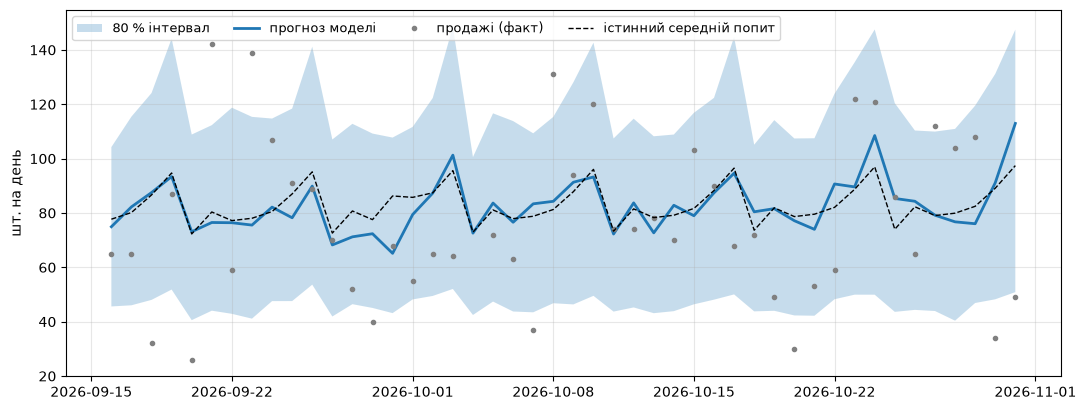

In [7]:
s = frame[(frame.store=='Київ-017') & (frame.sku=='MILK-1L') & (frame.date > '2026-09-15')].copy()
m, l, h = predict(models, s[FEATURES].to_numpy(float))
t = truth[(truth.store=='Київ-017') & (truth.sku=='MILK-1L') & (truth.date > '2026-09-15')]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.fill_between(s.date, l, h, alpha=0.25, label='80 % інтервал')
ax.plot(s.date, m, label='прогноз моделі', lw=2)
ax.plot(s.date, s.qty, '.', color='gray', label='продажі (факт)')
ax.plot(t.date, t.true_mean, '--', color='black', lw=1, label='істинний середній попит')
ax.set_ylabel('шт. на день'); ax.legend(loc='upper left', ncol=4, fontsize=9); ax.grid(alpha=0.3)
(ROOT / 'results').mkdir(exist_ok=True)
fig.tight_layout(); fig.savefig(ROOT / 'results' / 'forecast_milk.png', dpi=150); plt.show()

## 7. Передача результату наступному компоненту
Decision Engine отримує JSON від компонента ШІ і повертає маршрут рішення для модуля замовлень або черги менеджера.

In [8]:
f = svc.forecast('Київ-017', 'MILK-1L', '2026-10-24')
d = decide(f, 110, 4, 7, 12)
print(json.dumps({'forecast': f.as_dict(), 'decision': d.as_dict()}, ensure_ascii=False, indent=1))

{
 "forecast": {
  "store": "Київ-017",
  "sku": "MILK-1L",
  "origin": "2026-10-24",
  "daily": [
   85.34,
   84.31,
   79.17,
   76.74,
   76.04,
   91.1,
   112.94
  ],
  "point_7d": 605.6,
  "low_7d": 494.1,
  "high_7d": 699.0,
  "confidence": 0.831,
  "source": "ml_model",
  "flags": []
 },
 "decision": {
  "route": "auto_order",
  "order_qty": 540,
  "target_stock": 652.3,
  "reason": "впевненість 0.83 ≥ 0.75"
 }
}
